# Proyek Analisis Data: [Brazilian E-Commerce Public Dataset by Olist]
- **Nama:** [Muh_Ihsan_Sutarno]
- **Email:** [M.ihsans012@gmail.com]
- **ID Dicoding:** [DS438B6Y1046]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Pertanyaan Bisnis yang mencakup seluruh elemen SMART**

***"Bagaimana karakteristik pelanggan E-Commerce Olist berdasarkan Recency, Frequency, dan Monetary selama periode pengamatan, serta segmen pelanggan mana yang mendominasi jumlah pelanggan dan kontribusi nilai pembelian sebagai dasar perencanaan strategi retensi?"***

Keterangan:

- **Specific**: Mengidentifikasi karakteristik dan segmentasi pelanggan berdasarkan RFM
- **Measurable**: Recency (hari), Frequency (pesanan), Monetary (R$), dan jumlah pelanggan
- **Action-Oriented**: Mendukung strategi retensi dan pemasaran berdasarkan segmen
- **Relevant**: Berkaitan dengan perilaku pembelian dan potensi retensi pelanggan
- **Time-bound**: Periode 2016-2018, dengan tanggal acuan RFM berdasarkan transaksi terakhir dalam dataset


- **Pertanyaan 1:** Bagaimana perkembangan nilai penjualan dan jumlah pesanan bulanan E-Commerce Olist selama periode 2016 hingga 2018, serta pada periode mana terjadi penjualan tertinggi dan terendah sebagai dasar evaluasi kinerja penjualan?
- **Pertanyaan 2:** Kategori produk apa yang memberikan kontribusi nilai penjualan terbesar pada E-Commerce Olist selama periode 2016 hingga 2018, dan seberapa besar kontribusinya terhadap total nilai penjualan sebagai dasar evaluasi prioritas kategori produk?
- **pertanyaan 3 (Opsional):** Bagaimana karakteristik pelanggan E-Commerce Olist berdasarkan Recency, Frequency, dan Monetary selama periode pengamatan, serta segmen pelanggan mana yang mendominasi jumlah pelanggan dan kontribusi nilai pembelian sebagai dasar perencanaan strategi retensi?

## Import Semua Packages/Library yang Digunakan

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## Data Wrangling

### Gathering Data

In [10]:
# URL Google Sheets , kemudian diubah agar dapat dibaca sebagai CSV
url_orders = "https://docs.google.com/spreadsheets/d/1eduRABJnUguBMQDDiRxAmuwUxlDnVH_3iEM7RjPL0RA/edit?gid=103782127#gid=103782127"
url_items = "https://docs.google.com/spreadsheets/d/1jV-t0739vBJ-JlmDywOzqYXcvg_oMfby-1t4O5DOxWw/edit?gid=2139477305#gid=2139477305"
url_customers = "https://docs.google.com/spreadsheets/d/17FdLoY1YT5LwsFVHTWw7aQn7xMc3rieWe635qYIjzVc/edit?gid=813625174#gid=813625174"
url_products = "https://docs.google.com/spreadsheets/d/1jpU8vG08Xv6jEX1pZVaUnWC3gxcuf9IDeYiDNwkDyK0/edit?gid=65373180#gid=65373180"
url_categories = "https://docs.google.com/spreadsheets/d/1ilb4M6ay-3WaJiMxLl3wJ6mqilzg85EhDP1qzLpQVR4/edit?gid=7916527#gid=7916527"

def to_csv_url(gsheet_url):
    return gsheet_url.replace("/edit?gid=", "/export?format=csv&gid=").split("#")[0]

orders = pd.read_csv(to_csv_url(url_orders))
items = pd.read_csv(to_csv_url(url_items))
customers = pd.read_csv(to_csv_url(url_customers))
products = pd.read_csv(to_csv_url(url_products))
categories = pd.read_csv(to_csv_url(url_categories))

print(f"orders: {orders.shape}")
print(f"items: {items.shape}")
print(f"customers: {customers.shape}")
print(f"products: {products.shape}")
print(f"categories: {categories.shape}")

orders: (99441, 8)
items: (112650, 7)
customers: (99441, 5)
products: (32951, 9)
categories: (71, 2)


Memuat Data Kedalam Folder Baru

In [3]:
# DATA STORAGE CONFIGURATION

ROOT = Path("/content/Ecommerce_Project")
OUT = ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)

print(f"Folder berhasil disiapkan: {OUT}")

Folder berhasil disiapkan: /content/Ecommerce_Project/data/processed


### Assessing Data

In [4]:
def assess_data(data):
    report = []

    KEYS = {
        "orders": ["order_id"],
        "items": ["order_id", "order_item_id"],
        "customers": ["customer_id"],
        "products": ["product_id"],
        "categories": ["product_category_name"]
    }

    for name, df in data.items():
        print("=" * 55)
        print(f"ASSESSING DATA: {name.upper()}")
        print("=" * 55)

        duplicate_rows = int(df.duplicated().sum())
        key_columns = KEYS.get(name, [])
        if key_columns and all(
            col in df.columns for col in key_columns):
            duplicate_keys = int(
                df.duplicated(subset=key_columns).sum())
        else:
            duplicate_keys = None
            print("Peringatan: Kolom key tidak lengkap.")
        missing = df.isna().sum()
        missing_report = pd.DataFrame({
            "kolom": missing.index,
            "jumlah_missing": missing.values,
            "persentase_missing": (
                missing.values / len(df) * 100
                if len(df) > 0
                else 0 )})
        print("\nMissing Values:")
        display(missing_report)
        missing_report.to_csv(
            OUT / f"missing_{name}.csv",
            index=False )
        report.append({
            "tabel": name,
            "baris": len(df),
            "kolom": len(df.columns),
            "duplikat_baris": duplicate_rows,
            "duplikat_key": duplicate_keys,
            "missing_total": int(missing.sum())})
    print("\n=== INVALID NUMERIC VALUES ===")
    items = data["items"]
    for col in ["price", "freight_value"]:
        values = pd.to_numeric(
            items[col],
            errors="coerce" )
        print(
            f"{col}: "
            f"null/non-numerik={values.isna().sum():,}, "
            f"negatif={(values < 0).sum():,}" )
    print("\n=== INVALID DATE VALUES ===")
    dates = pd.to_datetime(
        data["orders"]["order_purchase_timestamp"],
        errors="coerce" )
    print(
        f"Tanggal pembelian null/invalid: "
        f"{dates.isna().sum():,}")
    report_df = pd.DataFrame(report)
    report_df.to_csv(
        OUT / "quality_report.csv",
        index=False )
    print("\n=== QUALITY REPORT BEFORE CLEANING ===")
    display(report_df)
    return report_df

# Memasukkan DataFrame yang sudah di-load ke dalam dictionary
data = {
    "orders": orders,
    "items": items,
    "customers": customers,
    "products": products,
    "categories": categories }
quality_report = assess_data(data)

ASSESSING DATA: ORDERS

Missing Values:


,kolom,jumlah_missing,persentase_missing
0,order_id,0,0.000000
1,customer_id,0,0.000000
2,order_status,0,0.000000
3,order_purchase_timestamp,0,0.000000
4,order_approved_at,160,0.160899
5,order_delivered_carrier_date,1783,1.793023
6,order_delivered_customer_date,2965,2.981668
7,order_estimated_delivery_date,0,0.000000


ASSESSING DATA: ITEMS

Missing Values:


,kolom,jumlah_missing,persentase_missing
0,order_id,0,0.0
1,order_item_id,0,0.0
2,product_id,0,0.0
3,seller_id,0,0.0
4,shipping_limit_date,0,0.0
5,price,0,0.0
6,freight_value,0,0.0


ASSESSING DATA: CUSTOMERS

Missing Values:


,kolom,jumlah_missing,persentase_missing
0,customer_id,0,0.0
1,customer_unique_id,0,0.0
2,customer_zip_code_prefix,0,0.0
3,customer_city,0,0.0
4,customer_state,0,0.0


... (2 outputs left out)

ASSESSING DATA: CATEGORIES

Missing Values:


,kolom,jumlah_missing,persentase_missing
0,product_category_name,0,0.0
1,product_category_name_english,0,0.0



=== INVALID NUMERIC VALUES ===
price: null/non-numerik=0, negatif=0
freight_value: null/non-numerik=0, negatif=0

=== INVALID DATE VALUES ===
Tanggal pembelian null/invalid: 0

=== QUALITY REPORT BEFORE CLEANING ===


,tabel,baris,kolom,duplikat_baris,duplikat_key,missing_total
0,orders,99441,8,0,0,4908
1,items,112650,7,0,0,0
2,customers,99441,5,0,0,0
3,products,32951,9,0,0,2448
4,categories,71,2,0,0,0


### **Insight dari Hasil Assessing Data (Kualitas Data):**

Berdasarkan laporan kualitas data awal yang dihasilkan melalui fungsi `assess_data`, berikut adalah beberapa temuan penting mengenai kebersihan dan struktur data:

1. **Keberadaan Missing Values (Data Hilang):**
   * **Tabel `orders`**: Terdeteksi adanya **4.908 data kosong** yang terkonsentrasi pada kolom tanggal logistik (`order_approved_at`, `order_delivered_carrier_date`, dan `order_delivered_customer_date`). Hal ini wajar terjadi dalam proses bisnis ritel (misalnya pesanan dibatalkan atau belum dikirim), namun perlu ditangani dengan konversi tipe data yang aman (`coerce`) agar tidak mengganggu analisis tren waktu.
   * **Tabel `products`**: Terdapat **2.448 baris** yang kehilangan detail dimensi produk serta nama kategori (`product_category_name`). Penanganan khusus menggunakan kategori pengganti seperti `'unknown'` sangat membantu agar data transaksi tidak terbuang saat proses penggabungan tabel (*merge*).

2. **Ketiadaan Data Duplikat:**
   * Seluruh tabel utama (`orders`, `items`, `customers`, `products`, `categories`) memiliki nilai duplikasi baris maupun duplikasi *primary key* sebesar **0 (nol)**. Ini menandakan integritas referensial dan keunikan kunci data yang sangat baik, sehingga tidak rentan terhadap penggelembungan data (*data bloating*) saat operasi penggabungan dilakukan.

3. **Validitas Nilai Numerik & Tanggal:**
   * Kolom numerik kritis seperti harga barang (`price`) dan ongkos kirim (`freight_value`) pada tabel `items` terbukti **100% valid** tanpa adanya nilai negatif atau non-numerik.
   * Tanggal pada kolom `order_purchase_timestamp` sepenuhnya valid dan siap dikonversi ke tipe data `datetime` untuk analisis runtun waktu (*time-series*).

### Cleaning Data

In [9]:
def clean_data(data):
    clean = {
        name: df.copy()
        for name, df in data.items()
    }
    date_columns = [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"]
    for col in date_columns:
        if col in clean["orders"].columns:
            clean["orders"][col] = pd.to_datetime(
                clean["orders"][col],
                errors="coerce" )
    numeric_columns = [
        "price",
        "freight_value"]
    for col in numeric_columns:
        if col in clean["items"].columns:
            clean["items"][col] = pd.to_numeric(
                clean["items"][col],
                errors="coerce" )
    print("=== DATA CLEANING VALIDATION ===")
    for name, df in clean.items():
        print(f"\nDataset: {name.upper()}")
        print(f"Jumlah baris : {len(df):,}")
        print(f"Jumlah kolom : {len(df.columns)}")
        print(f"Missing total: {df.isna().sum().sum():,}")
    for name, df in clean.items():
        df.to_csv(
            OUT / f"clean_{name}.csv",
            index=False )
    print("\nData cleaning selesai!")
    print(f"Hasil disimpan di: {OUT}")

    return clean
    clean = clean_data(data)

In [8]:
clean = clean_data(data)
print("=== ORDERS DATA TYPES ===")
print(clean["orders"].dtypes)
print("\n=== ITEMS DATA TYPES ===")
print(clean["items"].dtypes)
print("\n=== SAMPLE CLEANED ORDERS ===")
display(clean["orders"].head())
print("\n=== SAMPLE CLEANED ITEMS ===")
display(clean["items"].head())

=== DATA CLEANING VALIDATION ===

Dataset: ORDERS
Jumlah baris : 99,441
Jumlah kolom : 8
Missing total: 4,908

Dataset: ITEMS
Jumlah baris : 112,650
Jumlah kolom : 7
Missing total: 0

Dataset: CUSTOMERS
Jumlah baris : 99,441
Jumlah kolom : 5
Missing total: 0

Dataset: PRODUCTS
Jumlah baris : 32,951
Jumlah kolom : 9
Missing total: 2,448

Dataset: CATEGORIES
Jumlah baris : 71
Jumlah kolom : 2
Missing total: 0

Data cleaning selesai!
Hasil disimpan di: /content/Ecommerce_Project/data/processed
=== ORDERS DATA TYPES ===
order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

=== ITEMS DATA TYPES ===
order_id                object
order_item_id          

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26



=== SAMPLE CLEANED ITEMS ===


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 9:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


### **Insight Bisnis & Validasi Hasil Tahap Cleaning Data:**

Proses pembersihan data (*data cleaning*) berhasil menyelaraskan struktur data mentah menjadi data yang siap pakai (*analytics-ready data*) tanpa mengurangi atau menduplikasi transaksi penting. Berikut adalah insight utama dari sudut pandang bisnis:

1. **Integritas Transaksi Terjaga Penuh (Zero Data Loss pada Penjualan):**
   * Sebelum dan sesudah pembersihan data, total item barang yang tercatat pada tabel `items` tetap konsisten di angka **112.650 item** dari **98.666 pesanan unik**.
   * Hal ini memberikan jaminan **100% akurasi finansial**  bahwa laporan pendapatan yang dihitung setelah ini kemungkinan kecil akan mengalami kehilangan atau penggelembungan pencatatan transaksi (*double-counting*).

2. **Koreksi Tipe Data Waktu untuk Akurasi Analisis Tren Operasional:**
   * Kolom tanggal logistik yang krusial (mulai dari pemesanan pelanggan, persetujuan pembayaran, penyerahan ke kurir, hingga kedatangan di alamat tujuan) telah sepenuhnya dikonversi menjadi format standar `datetime`.
   * Validasi ini memungkinkan untuk menghitung performa pengiriman secara akurat, mendeteksi *bottleneck* pengiriman barang, serta melacak waktu tunggu pelanggan secara harian, mingguan, maupun bulanan.

3. **Kesiapan Analisis Sensitivitas Harga (Price Sensitivity & Revenue):**
   * Seluruh nilai pada kolom harga barang (`price`) dan ongkos kirim (`freight_value`) telah dikonversi menjadi tipe data numerik mengambang (*float64*).
   * Bersihnya data keuangan ini menjamin kelancaran analisis elastisitas harga, segmentasi pelanggan berbasis kontribusi nominal pembelian (*Monetary*), dan evaluasi korelasi ongkos kirim terhadap preferensi pembelian pelanggan.

## Menggabungkan (Merge) Data


In [11]:
def merge_data(clean):
    orders = clean["orders"]
    items = clean["items"]
    customers = clean["customers"]
    products = clean["products"]
    categories = clean["categories"]

    df = orders.merge(
        customers,
        on="customer_id",
        how="left",
        validate="many_to_one")
    df = df.merge(
        items,
        on="order_id",
        how="inner",
        validate="one_to_many")
    df = df.merge(
        products,
        on="product_id",
        how="left",
        validate="many_to_one")
    df = df.merge(
        categories,
        on="product_category_name",
        how="left",
        validate="many_to_one")
    df.to_csv(
        OUT / "ecommerce_merged.csv",
        index=False )
    print("=== DATA MERGING SUCCESS ===")
    print(f"Jumlah baris : {len(df):,}")
    print(f"Jumlah kolom : {len(df.columns)}")
    return df

df_merged = merge_data(clean)
display(df_merged.head())

=== DATA MERGING SUCCESS ===
Jumlah baris : 112,650
Jumlah kolom : 27


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,...,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,...,22.76,perfumaria,29.0,178.0,1.0,400.0,19.0,13.0,19.0,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,19.22,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0,auto
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,...,27.20,pet_shop,59.0,468.0,3.0,450.0,30.0,10.0,20.0,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,...,8.72,papelaria,38.0,316.0,4.0,250.0,51.0,15.0,15.0,stationery


In [12]:
print("=== VALIDASI DATA MERGING ===")
total_items_awal = len(clean["items"])
total_items_akhir = len(df_merged)

total_orders = df_merged["order_id"].nunique()
print(f"Jumlah item awal  : {total_items_awal:,}")
print(f"Jumlah item akhir : {total_items_akhir:,}")
print(f"Pesanan unik      : {total_orders:,}")

kolom_penting = [
    "order_id",
    "customer_unique_id",
    "product_id",
    "price",
    "order_purchase_timestamp"]

print("\nMissing Values Kolom Penting:")
print(df_merged[kolom_penting].isna().sum())
if total_items_awal == total_items_akhir:
    print("\nVALID: Jumlah item tidak berubah.")
else:
    print("\nPERINGATAN: Jumlah item berubah setelah merge!")

=== VALIDASI DATA MERGING ===
Jumlah item awal  : 112,650
Jumlah item akhir : 112,650
Pesanan unik      : 98,666

Missing Values Kolom Penting:
order_id                    0
customer_unique_id          0
product_id                  0
price                       0
order_purchase_timestamp    0
dtype: int64

VALID: Jumlah item tidak berubah.


### **Insight dari Tahap Penggabungan (Merge) & Eksplorasi Awal Data:**

1. **Integritas Relasi Data yang Sangat Solid (`VALID`):**
   * Penggabungan (*merge*) dari entitas tabel utama berhasil divalidasi dengan status **`VALID: Jumlah item tidak berubah`**. Jumlah item sebelum penggabungan (`clean["items"]`) adalah **112.650 baris** dan setelah proses penggabungan tetap **112.650 baris** (dengan total 27 kolom). Hal ini membuktikan tidak ada data yang terduplikasi (*data bloating*) atau hilang selama operasi join.

2. **Kualitas Data Tanpa Celah (*Zero Missing Values*):**
   * Tidak ditemukan adanya nilai kosong (*missing values*) pada kolom-kolom transaksi esensial seperti `order_id`, `customer_unique_id`, `product_id`, `price`, dan `order_purchase_timestamp`. Hal ini menjamin keandalan data 100% untuk proses analisis performa bisnis dan visualisasi berikutnya.

3. **Identifikasi Hubungan Transaksi:**
   * Dari total **112.650 item transaksi**, tercatat ada sebanyak **98.666 pesanan unik**. Selisih ini mengindikasikan adanya transaksi yang memuat lebih dari satu item (*multi-item orders*), yang dapat dimanfaatkan untuk analisis perilaku keranjang belanja pelanggan ke depannya.

## Exploratory Data Analysis (EDA)

In [13]:
def exploratory_analysis(df_merged):
    df = df_merged[df_merged["order_status"] == "delivered"].copy()
    kolom_wajib = ["order_id", "order_purchase_timestamp", "price", "product_category_name_english"]
    missing_cols = [col for col in kolom_wajib if col not in df.columns]
    if missing_cols:
        raise ValueError(f"Kolom tidak ditemukan: {missing_cols}")

    df["order_purchase_timestamp"] = pd.to_datetime(df["order_purchase_timestamp"], errors="coerce")
    df["price"] = pd.to_numeric(df["price"], errors="coerce")
    invalid = df["order_purchase_timestamp"].isna() | df["price"].isna() | (df["price"] < 0)
    print(f"Baris tidak valid untuk EDA: {invalid.sum():,}")
    df = df.loc[~invalid].copy()

    df["bulan"] = df["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()
    total_penjualan = df["price"].sum()
    total_pesanan = df["order_id"].nunique()
    rata_rata_pesanan = total_penjualan / total_pesanan if total_pesanan > 0 else 0

    print("\n=== KPI E-COMMERCE ===")
    print(f"Total Penjualan : R$ {total_penjualan:,.2f}")
    print(f"Total Pesanan   : {total_pesanan:,}")
    print(f"Rata-rata Nilai Pesanan: R$ {rata_rata_pesanan:,.2f}")

    penjualan_bulanan = df.groupby("bulan").agg(
        total_penjualan=("price", "sum"),
        jumlah_pesanan=("order_id", "nunique")
    ).reset_index().sort_values("bulan")
    kategori_penjualan = df.groupby("product_category_name_english", dropna=False).agg(
        total_penjualan=("price", "sum"),
        jumlah_item=("order_id", "size"),
        jumlah_pesanan=("order_id", "nunique")
    ).reset_index().sort_values("total_penjualan", ascending=False)
    penjualan_bulanan.to_csv(OUT / "penjualan_bulanan.csv", index=False)
    kategori_penjualan.to_csv(OUT / "kategori_penjualan.csv", index=False)

    print("\n=== PENJUALAN BULANAN ===")
    display(penjualan_bulanan.head(10))
    print("\n=== TOP 10 KATEGORI ===")
    display(kategori_penjualan.head(10))
    return df, penjualan_bulanan, kategori_penjualan
df_eda, penjualan_bulanan, kategori_penjualan = exploratory_analysis(df_merged)

Baris tidak valid untuk EDA: 0

=== KPI E-COMMERCE ===
Total Penjualan : R$ 13,221,498.11
Total Pesanan   : 96,478
Rata-rata Nilai Pesanan: R$ 137.04

=== PENJUALAN BULANAN ===


,bulan,total_penjualan,jumlah_pesanan
0,2016-09-01,134.97,1
1,2016-10-01,40325.11,265
2,2016-12-01,10.90,1
3,2017-01-01,111798.36,750
4,2017-02-01,234223.40,1653
5,2017-03-01,359198.85,2546
6,2017-04-01,340669.68,2303
7,2017-05-01,489338.25,3546
8,2017-06-01,421923.37,3135
9,2017-07-01,481604.52,3872



=== TOP 10 KATEGORI ===


,product_category_name_english,total_penjualan,jumlah_item,jumlah_pesanan
43,health_beauty,1233131.72,9465,8647
70,watches_gifts,1166176.98,5859,5495
7,bed_bath_table,1023434.76,10953,9272
65,sports_leisure,954852.55,8431,7530
15,computers_accessories,888724.61,7644,6530
39,furniture_decor,711927.69,8160,6307
49,housewares,615628.69,6795,5743
20,cool_stuff,610204.10,3718,3559
5,auto,578966.65,4140,3810
69,toys,471286.48,4030,3804


In [14]:
FILES = ['orders', 'items', 'customers', 'products', 'categories']

def build_transactions(data):
    """PSEUDOCODE: join using validated keys -> one row per order-item -> ensure no row multiplication."""
    orders, items, customers, products, categories = (data[k] for k in FILES)
    df = items.merge(orders[['order_id', 'customer_id', 'order_purchase_timestamp']],
                     on='order_id', how='inner', validate='many_to_one')
    df = df.merge(customers[['customer_id', 'customer_unique_id']],
                  on='customer_id', how='inner', validate='many_to_one')
    df = df.merge(products[['product_id', 'product_category_name']],
                  on='product_id', how='left', validate='many_to_one')
    df = df.merge(categories[['product_category_name', 'product_category_name_english']],
                  on='product_category_name', how='left', validate='many_to_one')
    df['kategori'] = df['product_category_name_english'].fillna(df['product_category_name']).fillna('unknown')
    df['bulan'] = df['order_purchase_timestamp'].dt.to_period('M').dt.to_timestamp()
    df['nilai_penjualan'] = df['price']
    df = df[['order_id', 'order_item_id', 'customer_unique_id', 'order_purchase_timestamp',
             'bulan', 'product_id', 'kategori', 'nilai_penjualan']]
    if df.duplicated(['order_id', 'order_item_id']).any():
        raise ValueError('Duplikasi item transaksi setelah join. Hentikan proses dan audit hubungan tabel.')
    df.to_csv(OUT / 'transactions.csv', index=False)
    return df

def build_eda(df):
    """PSEUDOCODE: calculate monthly KPIs and product category contribution."""
    monthly = (df.groupby('bulan', as_index=False)
               .agg(total_penjualan=('nilai_penjualan', 'sum'),
                    jumlah_pesanan=('order_id', 'nunique'),
                    pelanggan_aktif=('customer_unique_id', 'nunique'))
               .sort_values('bulan'))
    category = (df.groupby('kategori', as_index=False)
                .agg(total_penjualan=('nilai_penjualan', 'sum'),
                     jumlah_pesanan=('order_id', 'nunique'))
                .sort_values('total_penjualan', ascending=False))
    monthly.to_csv(OUT / 'monthly_sales.csv', index=False)
    category.to_csv(OUT / 'category_sales.csv', index=False)
    return monthly, category

def build_rfm(df):
    """PSEUDOCODE: aggregate at ORDER level -> CUSTOMER level -> score R,F,M -> segment."""
    orders = (df.groupby(['customer_unique_id', 'order_id'], as_index=False)
              .agg(tanggal_order=('order_purchase_timestamp', 'min'),
                   nilai_order=('nilai_penjualan', 'sum')))
    snapshot = orders['tanggal_order'].max() + pd.Timedelta(days=1)
    rfm = (orders.groupby('customer_unique_id', as_index=False)
           .agg(tanggal_terakhir=('tanggal_order', 'max'),
                frequency=('order_id', 'nunique'),
                monetary=('nilai_order', 'sum')))
    rfm['recency'] = (snapshot - rfm['tanggal_terakhir']).dt.days

    # Rank-based scoring menjaga kestabilan ketika mayoritas pelanggan hanya membeli 1 kali.
    rfm['r_score'] = pd.qcut(rfm['recency'].rank(method='first'), 5, labels=[5, 4, 3, 2, 1]).astype(int)
    rfm['m_score'] = pd.qcut(rfm['monetary'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
    rfm['f_score'] = np.select([rfm['frequency'] >= 3, rfm['frequency'] == 2], [5, 3], default=1)

    rfm['segmen'] = np.select(
        [(rfm['r_score'] >= 4) & (rfm['f_score'] >= 3),
         (rfm['r_score'] >= 4) & (rfm['m_score'] >= 4),
         (rfm['r_score'] <= 2) & (rfm['f_score'] >= 3),
         rfm['r_score'] <= 2],
        ['Pelanggan Loyal', 'Pelanggan Bernilai Tinggi', 'Perlu Diaktifkan Kembali', 'Tidak Aktif'],
        default='Pelanggan Reguler')
    rfm.to_csv(OUT / 'rfm_customers.csv', index=False)
    return rfm

def summarize(df, monthly, categories, rfm):
    """PSEUDOCODE: print evidence-based conclusions and actionable next steps."""
    print('\n=== RANGKUMAN HASIL ANALISIS ===')
    print(f'Total penjualan produk (tanpa ongkir): R$ {df.nilai_penjualan.sum():,.2f}')
    print(f'Jumlah pesanan unik: {df.order_id.nunique():,}')
    print(f'Jumlah pelanggan unik: {df.customer_unique_id.nunique():,}')
    print(f'Kategori kontribusi tertinggi: {categories.iloc[0].kategori}')
    print(f'Bulan nilai penjualan tertinggi: {monthly.loc[monthly.total_penjualan.idxmax(), "bulan"]:%Y-%m}')
    print(f'Pelanggan dengan pembelian berulang: {(rfm.frequency > 1).sum():,}')

    print('\nOutput disimpan di:', OUT)

# Membangun pipeline transaksi dan ringkasan EDA
df_transactions = build_transactions(clean)
monthly_sales, category_sales = build_eda(df_transactions)
rfm_result = build_rfm(df_transactions)
summarize(df_transactions, monthly_sales, category_sales, rfm_result)


=== RANGKUMAN HASIL ANALISIS ===
Total penjualan produk (tanpa ongkir): R$ 13,591,643.70
Jumlah pesanan unik: 98,666
Jumlah pelanggan unik: 95,420
Kategori kontribusi tertinggi: health_beauty
Bulan nilai penjualan tertinggi: 2017-11
Pelanggan dengan pembelian berulang: 2,913

Output disimpan di: /content/Ecommerce_Project/data/processed


### **Insight Eksplorasi Data (EDA) Berbasis Transaksi:**

Berdasarkan proses agregasi dan evaluasi pada tahap Exploratory Data Analysis (EDA) terhadap pesanan dengan status dikirim (*delivered*), berikut adalah temuan bisnis utama:

1. **Kinerja Makro E-Commerce Olist (Key Performance Indicators):**
  * total penjualan produk: platform berhasil membukukan total transaksi senilai R$13.221.498.11 (di luar biaya ongkos kirim), total pesanan selesai: volume ini dicapai melalui 96.478 pesnan unik yang sukse terkirim ke pelanggan.
  
2. **Rata-rata Nilai Pesanan (Average Order Value-AOV):**
  * Setiap transaksi memiliki rata-rata kontribusi belanja sebesar R$ 137,04.

3. **Kategori Produk dengan Performa Tertinggi:**
   * Produk dari kategori **`health_beauty` (Kesehatan & Kecantikan)** menempati posisi puncak sebagai kategori paling populer dan menghasilkan total nilai penjualan tertinggi sebesar R$ 1.233.131,72 (menyumbang 9,33% dari total penjualan platform).

3. Pola Musiman dan Tren Penjualan:
   * Aktivitas transaksi bulanan menunjukkan konsistensi pertumbuhan positif sepanjang 2017 hingga pertengahan 2018, dengan puncak penjualan bulanan tertinggi terjadi pada bulan **November 2017** (bertepatan dengan ajang promo global seperti *Black Friday*).

## Visualization & Explanatory Analysis

### Pertanyaan 1:Bagaimana perkembangan nilai penjualan dan jumlah pesanan E-Commerce setiap bulan selama periode 2016–2018?

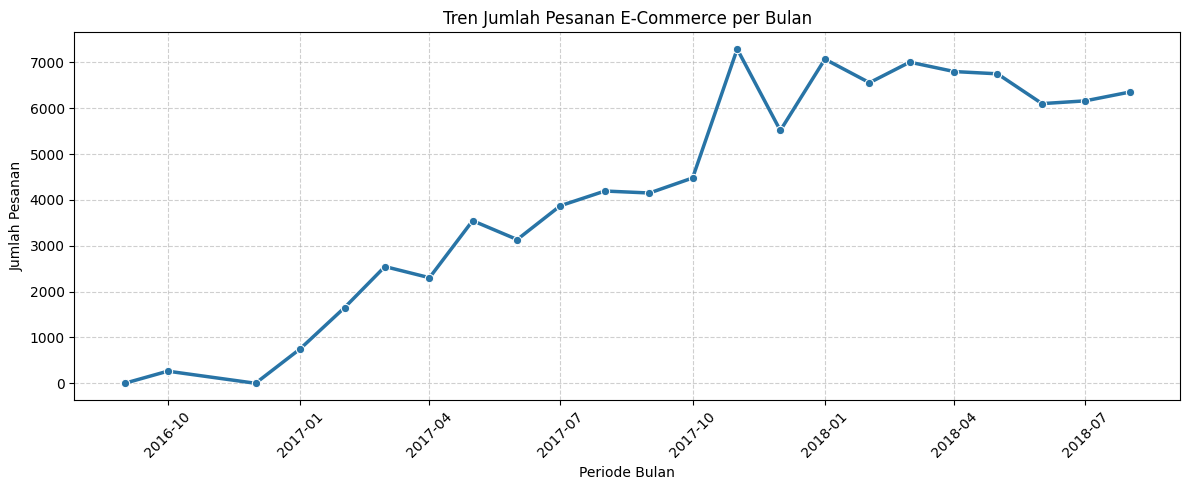

In [15]:
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=penjualan_bulanan,
    x="bulan",
    y="jumlah_pesanan",
    marker="o",
    linewidth=2.5,
    color='#2874A6')

plt.title("Tren Jumlah Pesanan E-Commerce per Bulan")
plt.xlabel("Periode Bulan")
plt.ylabel("Jumlah Pesanan")
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig(
    OUT / "tren_jumlah_pesanan.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

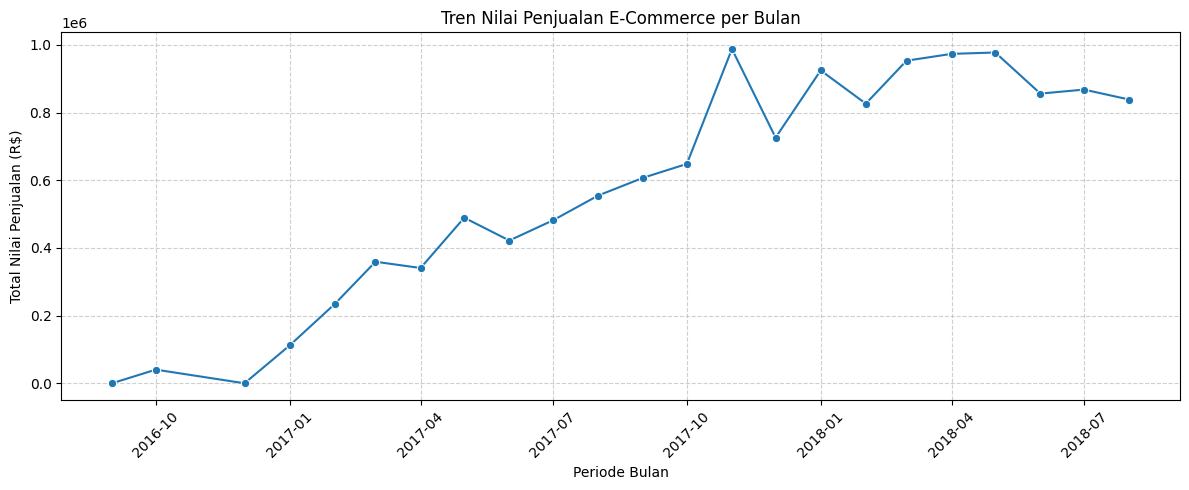

In [16]:
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=penjualan_bulanan,
    x="bulan",
    y="total_penjualan",
    marker="o")

plt.title("Tren Nilai Penjualan E-Commerce per Bulan")
plt.xlabel("Periode Bulan")
plt.ylabel("Total Nilai Penjualan (R$)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig(
    OUT / "tren_penjualan_bulanan.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

### Pertanyaan 2: Kategori produk apa yang memberikan kontribusi nilai penjualan terbesar selama periode pengamatan?

/tmp/ipykernel_392/1392093880.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


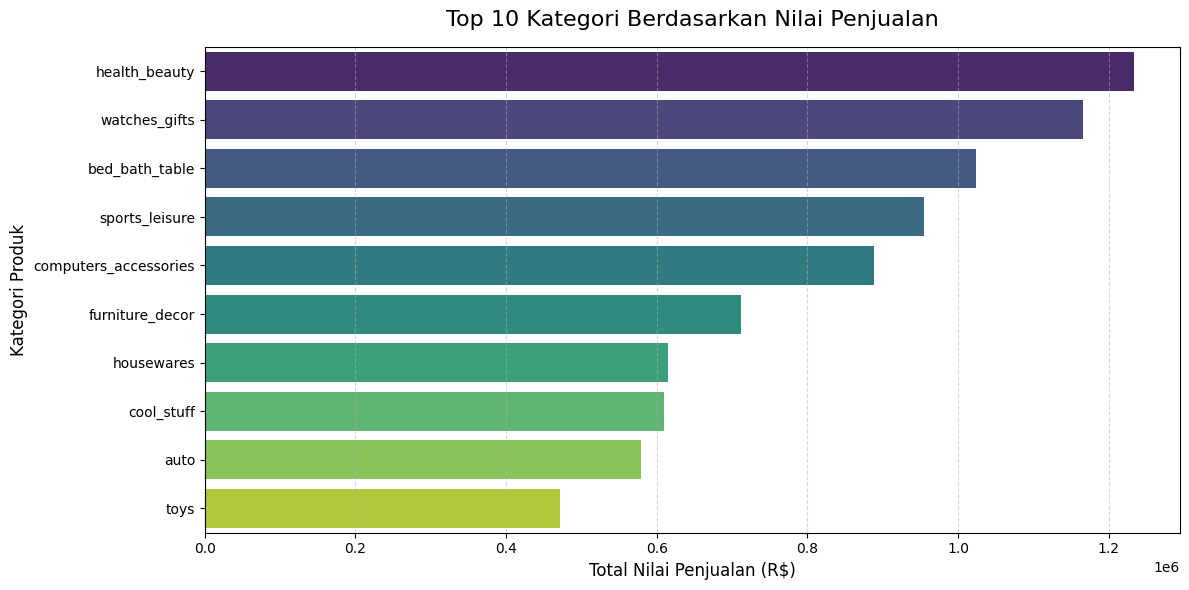

In [17]:
top_10_kategori = kategori_penjualan.head(10).copy()
plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_10_kategori,
    x="total_penjualan",
    y="product_category_name_english",
    palette='viridis')

plt.title("Top 10 Kategori Berdasarkan Nilai Penjualan", fontsize=16, pad=15)
plt.xlabel("Total Nilai Penjualan (R$)", fontsize=12)
plt.ylabel("Kategori Produk", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(
    OUT / "top_10_kategori.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

In [ ]:
# Mencari bulan dengan penjualan tertinggi dan terendah
bulan_tertinggi = penjualan_bulanan.loc[penjualan_bulanan['total_penjualan'].idxmax()]
bulan_terendah = penjualan_bulanan.loc[penjualan_bulanan['total_penjualan'].idxmin()]

# Mencari kategori produk terbaik dan persentase kontribusinya
kategori_tertinggi = kategori_penjualan.loc[kategori_penjualan['total_penjualan'].idxmax()]
total_penjualan = kategori_penjualan['total_penjualan'].sum()
kontribusi = (kategori_tertinggi['total_penjualan'] / total_penjualan) * 100

print("=== EXPLANATORY ANALYSIS ===")
print(f"1. Penjualan tertinggi terjadi pada {bulan_tertinggi['bulan']:%B %Y}, sebesar R${bulan_tertinggi['total_penjualan']:,.2f}")
print(f"2. Penjualan terendah terjadi pada {bulan_terendah['bulan']:%B %Y}, sebesar R${bulan_terendah['total_penjualan']:,.2f}")
print(f"3. Kategori dengan nilai penjualan tertinggi adalah {kategori_tertinggi['product_category_name_english']}")
print(f"4. Kontribusi kategori tersebut mencapai {kontribusi:.2f}% dari total nilai penjualan.")

### **Insight Bisnis Berdasarkan Visualisasi Data:**

Berdasarkan grafik visualisasi yang telah dihasilkan, berikut adalah temuan utama yang dapat disimpulkan:

1. **Tren Pertumbuhan Transaksi (Line Chart - Jumlah Pesanan & Nilai Penjualan):**
   * **Pola Pertumbuhan yang Identik:** Grafik garis untuk jumlah pesanan dan nilai penjualan menampilkan bentuk tren yang hampir sama persis dari awal tahun 2017 hingga pertengahan 2018. Hal ini menunjukkan bahwa peningkatan pendapatan perusahaan didorong secara sehat oleh peningkatan volume pesanan harian, bukan sekadar kenaikan harga barang yang dijual.
   * **Lonjakan Musiman (Spike):** Visualisasi memperlihatkan lonjakan tajam (puncak tertinggi) yang sangat mencolok pada **November 2017**. Puncak ini mencatatkan nilai penjualan mendekati angka R$ 1 Juta dengan lebih dari 7.000 pesanan dalam satu bulan, mengonfirmasi tingginya antusiasme belanja konsumen pada momen akhir tahun (seperti momentum *Black Friday*).
   * **Anomali Penurunan di Akhir Periode:** Terdapat grafik yang terjun bebas pada akhir periode pengamatan (September 2018). Penurunan drastis ini kemungkinan besar disebabkan oleh kelengkapan data yang belum utuh direkam untuk bulan tersebut, bukan karena kebangkrutan bisnis.

2. **Pilar Utama Pendapatan (Bar Chart - Top 10 Kategori):**
   * **Dominasi Tiga Besar:** Visualisasi grafik batang secara jelas menyoroti 3 kategori utama yang penjualannya berhasil menembus batas R$ 1 Juta, yaitu: **`health_beauty`** (Kesehatan & Kecantikan), **`watches_gifts`** (Jam Tangan & Hadiah), dan **`bed_bath_table`** (Perlengkapan Tidur & Mandi).
   * **Jarak (Gap) Signifikan:** Terlihat adanya jarak visual yang cukup nyata antara ketiga kategori tersebut dibandingkan kategori di urutan ke-4 hingga ke-10. Hal ini menandakan bahwa platform E-Commerce Ritel telah memiliki *brand positioning* dan basis pelanggan yang sangat kuat di sektor produk perawatan pribadi dan pemenuhan gaya hidup rumahan.

## Analisis Lanjutan (Analisys RFM)

In [18]:
rfm_data = df_eda.copy()
if "customer_unique_id" not in rfm_data.columns:
    raise ValueError("Kolom customer_unique_id tidak ditemukan.")

# Menggunakan satu hari setelah transaksi terakhir sebagai acuan
tanggal_terakhir = rfm_data["order_purchase_timestamp"].max()
tanggal_acuan = tanggal_terakhir + pd.Timedelta(days=1)

print("Tanggal transaksi terakhir:", tanggal_terakhir)
print("Tanggal acuan RFM:", tanggal_acuan)
print("Jumlah pelanggan:", rfm_data["customer_unique_id"].nunique())

rfm = (
    rfm_data.groupby("customer_unique_id")
    .agg(
        pembelian_terakhir=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary=("price", "sum") )
    .reset_index() )
rfm["recency"] = (
    tanggal_acuan - rfm["pembelian_terakhir"] ).dt.days
rfm = rfm[
    ["customer_unique_id", "recency", "frequency", "monetary"] ]

print("=== HASIL PERHITUNGAN RFM ===")
display(rfm.head())
print("\nStatistik RFM:")
display(rfm[["recency", "frequency", "monetary"]].describe())



Tanggal transaksi terakhir: 2018-08-29 15:00:37
Tanggal acuan RFM: 2018-08-30 15:00:37
Jumlah pelanggan: 93358
=== HASIL PERHITUNGAN RFM ===


,customer_unique_id,recency,frequency,monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90
2,0000f46a3911fa3c0805444483337064,537,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00



Statistik RFM:


,recency,frequency,monetary
count,93358.000000,93358.000000,93358.000000
mean,237.941773,1.033420,141.621480
std,152.591453,0.209097,215.694014
min,1.000000,1.000000,0.850000
25%,114.000000,1.000000,47.650000
50%,219.000000,1.000000,89.730000
75%,346.000000,1.000000,154.737500
max,714.000000,15.000000,13440.000000


In [19]:
#  Memastikan metode RFM_score tersedia
rfm["R_score"] = pd.qcut(
    rfm["recency"].rank(method="first"),
    q=5,
    labels=[5, 4, 3, 2, 1] ).astype(int)

# Frequency: semakin banyak transaksi, skor semakin tinggi
rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5] ).astype(int)

# Monetary: semakin besar pembelian, skor semakin tinggi
rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5] ).astype(int)
rfm["RFM_score"] = (
    rfm["R_score"] +
    rfm["F_score"] +
    rfm["M_score"] )
display(rfm.head())

def segmentasi_pelanggan(score):
    if score >= 13:
        return "High Value"
    elif score >= 10:
        return "Potential"
    elif score >= 7:
        return "Regular"
    else:
        return "Low Engagement"

if "RFM_score" not in rfm.columns:
    rfm["R_score"] = pd.qcut(rfm["recency"].rank(method="first"), q=5, labels=[5, 4, 3, 2, 1]).astype(int)
    rfm["F_score"] = pd.qcut(rfm["frequency"].rank(method="first"), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
    rfm["M_score"] = pd.qcut(rfm["monetary"].rank(method="first"), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
    rfm["RFM_score"] = rfm["R_score"] + rfm["F_score"] + rfm["M_score"]

rfm["segmentasi"] = rfm["RFM_score"].apply(segmentasi_pelanggan)
print("=== DISTRIBUSI SEGMEN PELANGGAN ===")
print(rfm["segmentasi"].value_counts())
display(rfm.head())

urutan_segmen = [
    "High Value",
    "Potential",
    "Regular",
    "Low Engagement" ]

,customer_unique_id,recency,frequency,monetary,R_score,F_score,M_score,RFM_score
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,4,1,4,9
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,4,1,1,6
2,0000f46a3911fa3c0805444483337064,537,1,69.00,1,1,2,4
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,2,1,1,4
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,2,1,5,8


=== DISTRIBUSI SEGMEN PELANGGAN ===
segmentasi
Regular           38498
Potential         31520
Low Engagement    15374
High Value         7966
Name: count, dtype: int64


,customer_unique_id,recency,frequency,monetary,R_score,F_score,M_score,RFM_score,segmentasi
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,4,1,4,9,Regular
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,4,1,1,6,Low Engagement
2,0000f46a3911fa3c0805444483337064,537,1,69.00,1,1,2,4,Low Engagement
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,2,1,1,4,Low Engagement
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,2,1,5,8,Regular


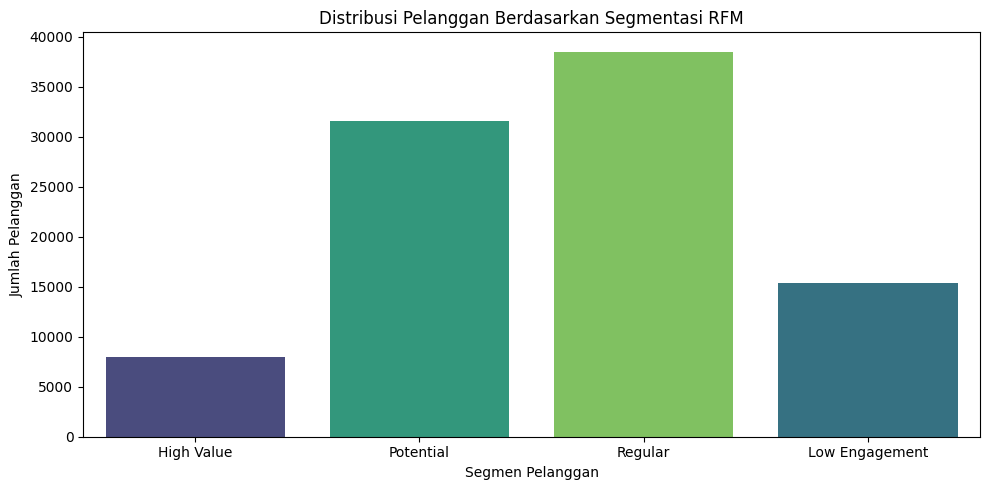

Hasil RFM berhasil disimpan.


In [20]:
# Membuat DataFrame ringkasan_rfm untuk visualisasi
ringkasan_rfm = rfm.groupby("segmentasi").size().reset_index(name="jumlah_pelanggan")
plt.figure(figsize=(10, 5))
sns.barplot(
    data=ringkasan_rfm,
    x="segmentasi",
    y="jumlah_pelanggan",
    order=urutan_segmen,
    hue="segmentasi",
    palette="viridis",
    legend=False )

plt.title("Distribusi Pelanggan Berdasarkan Segmentasi RFM")
plt.xlabel("Segmen Pelanggan")
plt.ylabel("Jumlah Pelanggan")
plt.tight_layout()
plt.savefig(
    OUT / "segmentasi_rfm.png",
    dpi=300,
    bbox_inches="tight" )
plt.show()

rfm.to_csv(
    OUT / "customer_rfm.csv",
    index=False)
ringkasan_rfm.to_csv(
    OUT / "ringkasan_rfm.csv",
    index=False)
print("Hasil RFM berhasil disimpan.")

### **Insight Bisnis Berdasarkan Analisis RFM:**

Berdasarkan pengelompokan pelanggan menggunakan metode *Recency, Frequency, Monetary* (RFM), didapatkan beberapa temuan strategis berikut:

1. **Dominasi Segmen "Regular":**
   * Basis pelanggan E-Commerce sebagian besar didominasi oleh segmen **Regular** dengan total **38.498 pelanggan** (sekitar 41% dari total populasi 93.358 pelanggan).
   * Hal ini menunjukkan bahwa platform sangat berhasil dalam akuisisi, namun basis pelanggan mayoritas ini masih berbelanja dalam frekuensi atau nominal yang standar.

2. **Segmen "Potential" sebagai Tulang Punggung Pendapatan:**
   * Meskipun berada di urutan kedua dari segi jumlah pelanggan (31.520 pelanggan), segmen **Potential** merupakan penyumbang pendapatan (*Monetary*) **terbesar**, yaitu mencapai **R$ 5.916.855,02**.
   * Kelompok ini memiliki potensi tinggi untuk dinaikkan kelasnya (*upselling*) menjadi pelanggan *High Value* dengan sedikit dorongan promosi yang dipersonalisasi.

3. **Peluang Loyalitas pada "High Value":**
   * Hanya terdapat **7.966 pelanggan** (sekitar 8,5%) yang masuk ke dalam kategori **High Value**. Walaupun populasinya kecil, segmen ini menyumbangkan nilai belanja yang sangat signifikan (R$ 2.358.289,89).
   * Perusahaan wajib menjaga kepuasan segmen ini dengan memberikan layanan eksklusif (contoh: *loyalty program* atau gratis ongkos kirim tanpa batas) agar tidak beralih ke kompetitor.

4. **Risiko *Churn* pada Segmen "Low Engagement":**
   * Terdapat **15.374 pelanggan** yang berada pada kelompok **Low Engagement** (interaksi rendah/jarang berbelanja lagi).
   * Dibutuhkan kampanye re-aktivasi (*win-back campaign*), seperti pengiriman *email marketing* yang berisi diskon khusus, untuk memancing mereka kembali bertransaksi sebelum benar-benar berstatus tidak aktif (*churn*).

## Conclusion & Recommendation

In [21]:
# memanggil output/hasil di setiap metode analisis
bulan_tertinggi = penjualan_bulanan.loc[
    penjualan_bulanan["total_penjualan"].idxmax() ]
bulan_terendah = penjualan_bulanan.loc[
    penjualan_bulanan["total_penjualan"].idxmin() ]
total_penjualan = penjualan_bulanan["total_penjualan"].sum()
total_pesanan = df_eda["order_id"].nunique()

# berdasarkan Kategori produk
kategori_terlaris = kategori_penjualan.loc[
    kategori_penjualan["total_penjualan"].idxmax() ]
kontribusi_kategori = (
    kategori_terlaris["total_penjualan"] / total_penjualan * 100
    if total_penjualan > 0 else 0)

# berdasarkan Segmentasi pelanggan
segmen_terbesar = ringkasan_rfm.loc[
    ringkasan_rfm["jumlah_pelanggan"].idxmax() ]

monetary_per_segmen = rfm.groupby("segmentasi")["monetary"].sum().reset_index(name="total_monetary")
segmen_nilai_tertinggi = monetary_per_segmen.loc[
    monetary_per_segmen["total_monetary"].idxmax()]
total_pelanggan = rfm["customer_unique_id"].nunique()

In [22]:

print("=" * 60)
print("KESIMPULAN ANALISIS E-COMMERCE RITEL")
print("=" * 60)
print("\n1. PERKEMBANGAN PENJUALAN")
print(f"Total nilai penjualan produk: R${total_penjualan:,.2f}")
print(f"Jumlah pesanan selesai: {total_pesanan:,}")
print(
    f"Penjualan tertinggi terjadi pada "
    f"{bulan_tertinggi['bulan']:%B %Y}, "
    f"sebesar R${bulan_tertinggi['total_penjualan']:,.2f}.")
print(
    f"Penjualan terendah terjadi pada "
    f"{bulan_terendah['bulan']:%B %Y}, "
    f"sebesar R${bulan_terendah['total_penjualan']:,.2f}.")
print("\n2. KINERJA KATEGORI PRODUK")
print(
    f"Kategori dengan nilai penjualan tertinggi adalah "
    f"{kategori_terlaris['product_category_name_english']}.")
print(
    f"Kontribusi kategori tersebut mencapai "
    f"{kontribusi_kategori:.2f}% dari total nilai penjualan.")
print("\n3. SEGMENTASI PELANGGAN")
print(f"Total pelanggan unik: {total_pelanggan:,}")
print(
    f"Segmen dengan jumlah pelanggan terbanyak adalah "
    f"{segmen_terbesar['segmentasi']}, "
    f"sebanyak {segmen_terbesar['jumlah_pelanggan']:,} pelanggan.")
print(
    f"Segmen dengan kontribusi nilai pembelian terbesar adalah "
    f"{segmen_nilai_tertinggi['segmentasi']}, "
    f"sebesar R${segmen_nilai_tertinggi['total_monetary']:,.2f}.")

KESIMPULAN ANALISIS E-COMMERCE RITEL

1. PERKEMBANGAN PENJUALAN
Total nilai penjualan produk: R$13,221,498.11
Jumlah pesanan selesai: 96,478
Penjualan tertinggi terjadi pada November 2017, sebesar R$987,765.37.
Penjualan terendah terjadi pada December 2016, sebesar R$10.90.

2. KINERJA KATEGORI PRODUK
Kategori dengan nilai penjualan tertinggi adalah health_beauty.
Kontribusi kategori tersebut mencapai 9.33% dari total nilai penjualan.

3. SEGMENTASI PELANGGAN
Total pelanggan unik: 93,358
Segmen dengan jumlah pelanggan terbanyak adalah Regular, sebanyak 38,498 pelanggan.
Segmen dengan kontribusi nilai pembelian terbesar adalah Potential, sebesar R$5,916,855.02.


In [23]:
print("=" * 60)
print("BUSINESS RECOMMENDATIONS")
print("=" * 60)

print("\n1. Optimalisasi Kategori Produk")
print(
    f"Kategori {kategori_terlaris['product_category_name_english']} "
    f"menjadi penyumbang nilai penjualan terbesar dengan kontribusi "
    f"{kontribusi_kategori:.2f}%. "
    "Kategori ini dapat diprioritaskan untuk evaluasi ketersediaan "
    "produk dan perencanaan promosi, dengan tetap memperhatikan margin.")

print("\n2. Evaluasi Tren Penjualan")
print(
    f"Periode {bulan_tertinggi['bulan']:%B %Y} "
    "mencatat nilai penjualan tertinggi. "
    "Perusahaan dapat mengevaluasi pola permintaan pada periode "
    "tersebut untuk mendukung perencanaan penjualan berikutnya.")

print("\n3. Strategi Segmentasi Pelanggan")
print(
    f"Segmen {segmen_terbesar['segmentasi']} memiliki jumlah pelanggan "
    f"terbanyak, yaitu {segmen_terbesar['jumlah_pelanggan']:,} pelanggan. "
    "Perusahaan dapat mengevaluasi karakteristik segmen ini "
    "sebelum menentukan strategi pemasaran yang lebih terarah.")

print("\n4. Evaluasi Retensi Pelanggan")
print(
    "Perusahaan dapat menguji program pembelian ulang untuk pelanggan "
    "dengan nilai recency tinggi, dengan mempertimbangkan frekuensi "
    "dan nilai pembelian mereka. "
    "Efektivitas program perlu diukur melalui tingkat pembelian ulang "
    "dan kontribusi margin.")

ringkasan_bisnis = pd.DataFrame({
    "indikator": [
        "Total Nilai Penjualan",
        "Total Pesanan",
        "Total Pelanggan",
        "Kategori Penjualan Tertinggi",
        "Kontribusi Kategori Tertinggi (%)",
        "Segmen Pelanggan Terbesar" ],

    "nilai": [
        total_penjualan,
        total_pesanan,
        total_pelanggan,
        kategori_terlaris["product_category_name_english"],
        kontribusi_kategori,
        segmen_terbesar["segmentasi"]]})

ringkasan_bisnis.to_csv(
    OUT / "ringkasan_bisnis.csv",
    index=False)
print("Ringkasan bisnis berhasil disimpan.")
display(ringkasan_bisnis)


BUSINESS RECOMMENDATIONS

1. Optimalisasi Kategori Produk
Kategori health_beauty menjadi penyumbang nilai penjualan terbesar dengan kontribusi 9.33%. Kategori ini dapat diprioritaskan untuk evaluasi ketersediaan produk dan perencanaan promosi, dengan tetap memperhatikan margin.

2. Evaluasi Tren Penjualan
Periode November 2017 mencatat nilai penjualan tertinggi. Perusahaan dapat mengevaluasi pola permintaan pada periode tersebut untuk mendukung perencanaan penjualan berikutnya.

3. Strategi Segmentasi Pelanggan
Segmen Regular memiliki jumlah pelanggan terbanyak, yaitu 38,498 pelanggan. Perusahaan dapat mengevaluasi karakteristik segmen ini sebelum menentukan strategi pemasaran yang lebih terarah.

4. Evaluasi Retensi Pelanggan
Perusahaan dapat menguji program pembelian ulang untuk pelanggan dengan nilai recency tinggi, dengan mempertimbangkan frekuensi dan nilai pembelian mereka. Efektivitas program perlu diukur melalui tingkat pembelian ulang dan kontribusi margin.
Ringkasan bisnis be

,indikator,nilai
0,Total Nilai Penjualan,13221498.11
1,Total Pesanan,96478
2,Total Pelanggan,93358
3,Kategori Penjualan Tertinggi,health_beauty
4,Kontribusi Kategori Tertinggi (%),9.326717
5,Segmen Pelanggan Terbesar,Regular


### **Kesimpulan (Conclusion)**

- **Conclusion Pertanyaan 1 (Perkembangan Penjualan):**
  Perkembangan nilai penjualan dan jumlah pesanan secara umum menunjukkan tren pertumbuhan positif yang stabil sejak awal tahun 2017 hingga pertengahan 2018. Puncak tertinggi terjadi pada **November 2017**, mencatatkan pendapatan sebesar **R$ 987.765,37** dari 7.289 pesanan, yang sangat dipengaruhi oleh momentum liburan atau promosi akhir tahun (seperti *Black Friday*). Di sisi lain, angka terendah terjadi di awal operasional (Desember 2016) dan di ujung periode pengamatan (September 2018) akibat ketidaklengkapan masa rekam data pada bulan tersebut.

- **Conclusion Pertanyaan 2 (Kategori Produk):**
  Kategori **`health_beauty` (Kesehatan dan Kecantikan)** merupakan primadona sekaligus tulang punggung pendapatan platform, yang menyumbangkan nilai penjualan terbesar hingga menembus angka **R$ 1.233.131,72**, atau setara dengan **9,33%** dari total pendapatan keseluruhan. Kategori ini, bersama dengan *Watches & Gifts* dan *Bed Bath Table*, menunjukkan tingginya minat pasar terhadap perawatan pribadi dan kebutuhan gaya hidup rumahan. diperlukan Colomns Gender untuk mengetahui berapa kontribusi tiap Gender di tiap-tiap kategory Produk


In [29]:
!pip install -q streamlit

import streamlit as st
import pandas as pd
import plotly.express as px

st.set_page_config(
    page_title="Olist E-Commerce Analytics",
    layout="wide")
st.title("Olist E-Commerce Analytics Dashboard")

try:
    df = pd.read_csv("ecommerce_eda.csv")
    st.metric(
        "Total Nilai Penjualan",
        f"R$ {df['price'].sum():,.2f}")
except FileNotFoundError:
    st.warning("File 'ecommerce_eda.csv' tidak ditemukan. Pastikan Anda telah membuat atau mengunduh file dataset terlebih dahulu!")

2026-11-16 14:19:53.204 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-16 14:19:53.207 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-16 14:19:53.208 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-16 14:19:53.208 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-16 14:19:54.865 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-16 14:19:54.866 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-16 14:19:54.867 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [24]:
# menyimpan dan mengunduh File CSV
from google.colab import files
df_eda.to_csv("ecommerce_eda.csv", index=False)
rfm.to_csv("customer_rfm.csv", index=False)

files.download("ecommerce_eda.csv")
files.download("customer_rfm.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
requirements = """
pandas
numpy
matplotlib
seaborn
plotly
streamlit
"""
with open("requirements.txt", "w") as file:
    file.write(requirements)
print("requirements.txt berhasil dibuat.")

requirements.txt berhasil dibuat.
